# COCO-MLT: the RTN skeleton across encoders (summary)

Reads the results saved by the three COCO-MLT notebooks and trains
nothing. It only compares results that come from the same skeleton: the
same `rtn_skeleton.py` (its fingerprint), the same split, labels and
relation types. Run it after the encoder notebooks; it also works when
only some of them are done.

Project folder: c:\Users\Admin\Documents\MSc-Project---RTN
Skeleton: c:\Users\Admin\Documents\MSc-Project---RTN\RTN\rtn_skeleton.py (version 1)


,check,passed
0,same skeleton (fingerprint ac9d3bf7088a),True
1,same split,True
2,same labels,True
3,same relations,True


COCO-MLT, CLIP ViT-B/16: RTN vs MulSupCon NOT SHOWN (tail AP +0.44 [-0.33, +1.17], higher in 2 of 3 seeds; related-class gap C1 -0.30 [-0.78, +0.05], C2 -0.04 [-0.52, +0.49]; head AP -0.38; overall AP -0.15 [-0.49, +0.18])
COCO-MLT, ViT-B/16 (ImageNet): RTN vs MulSupCon NOT SHOWN (tail AP -0.03 [-0.95, +0.75], higher in 1 of 3 seeds; related-class gap C1 -0.27 [-0.60, +0.04], C2 -0.58 [-1.21, +0.01]; head AP -0.85; overall AP -0.43 [-0.80, -0.08])
COCO-MLT, ResNet-50 (ImageNet, input 448): RTN vs MulSupCon NOT SHOWN (tail AP -0.30 [-1.39, +0.77], higher in 2 of 3 seeds; related-class gap C1 -0.31 [-0.81, +0.14], C2 -0.32 [-1.62, +0.89]; head AP +0.06; overall AP -0.27 [-0.69, +0.16])


,dataset,encoder,MulSupCon all / tail mAP,RTN all / tail mAP,tail AP change,higher tail mAP (seeds),head AP change,all AP change,"gap change, C1","gap change, C2",verdict
0,COCO-MLT,CLIP ViT-B/16,62.99 / 64.27,62.84 / 64.71,"+0.44 [-0.33, +1.17]",2/3,"-0.38 [-0.90, +0.18]","-0.15 [-0.49, +0.18]","-0.30 [-0.78, +0.05]","-0.04 [-0.52, +0.49]",NOT SHOWN
1,COCO-MLT,ViT-B/16 (ImageNet),54.97 / 54.15,54.54 / 54.12,"-0.03 [-0.95, +0.75]",1/3,"-0.85 [-1.37, -0.31]","-0.43 [-0.80, -0.08]","-0.27 [-0.60, +0.04]","-0.58 [-1.21, +0.01]",NOT SHOWN
2,COCO-MLT,"ResNet-50 (ImageNet, input 448)",52.91 / 47.62,52.64 / 47.32,"-0.30 [-1.39, +0.77]",2/3,"+0.06 [-0.44, +0.55]","-0.27 [-0.69, +0.16]","-0.31 [-0.81, +0.14]","-0.32 [-1.62, +0.89]",NOT SHOWN


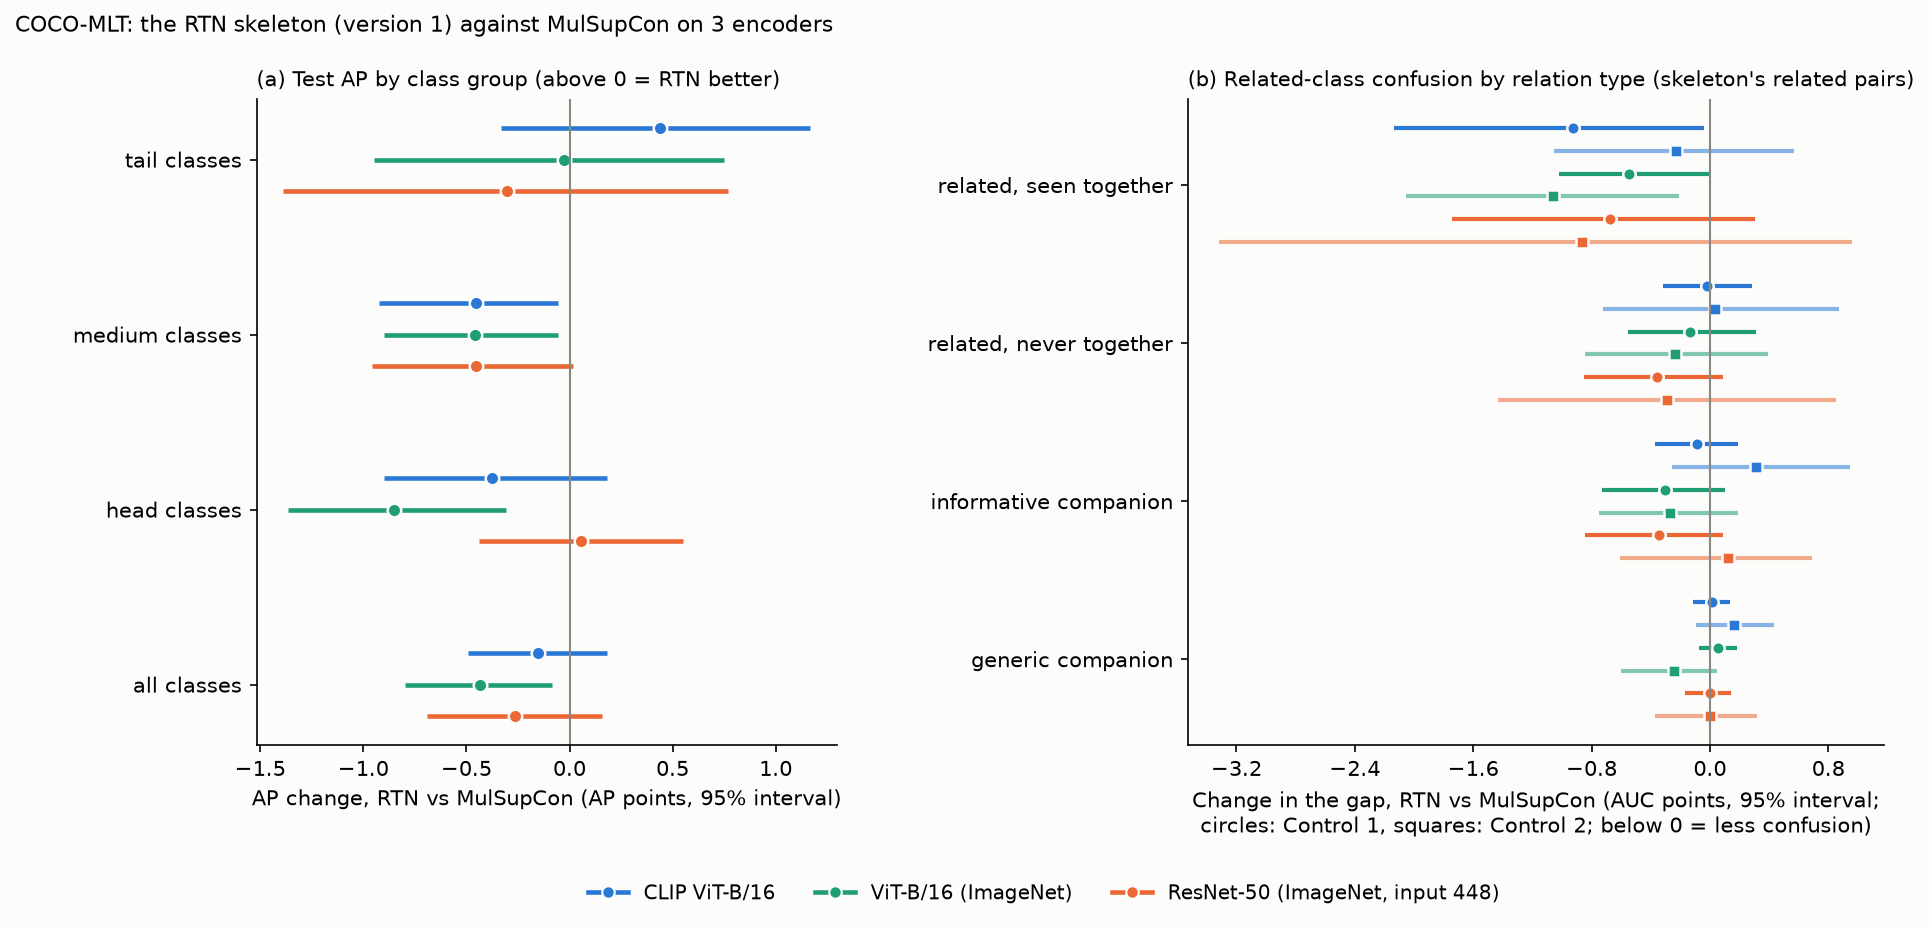

Saved the table, figure and summary.txt to c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\summary


In [1]:
import importlib
import os
import sys

# This notebook can sit in the project folder or in a folder inside it. The
# project folder is the one with coco_mlt/ and the round 6 files; every path
# below is relative to it.
HERE = os.path.abspath("")
PROJECT = next((p for p in (HERE, os.path.dirname(HERE))
                if os.path.isdir(os.path.join(p, "coco_mlt"))
                and os.path.exists(os.path.join(p, "relation_contrastive_runs.py"))), None)
if PROJECT is None:
    raise SystemExit("Put this notebook in the project folder (the one with coco_mlt/ and "
                     "relation_contrastive_runs.py) or in a folder inside it.")
copies = {os.path.join(p, "rtn_skeleton.py") for p in (HERE, PROJECT)
          if os.path.exists(os.path.join(p, "rtn_skeleton.py"))}
if not copies:
    raise SystemExit("rtn_skeleton.py not found next to this notebook or in the project folder.")
if len(copies) > 1 and len({open(c, "rb").read() for c in copies}) > 1:
    raise SystemExit("There are two different copies of rtn_skeleton.py; keep only one.")
for p in (HERE, PROJECT):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(PROJECT)

import rtn_skeleton as sk
importlib.reload(sk)
print(f"Project folder: {PROJECT}\nSkeleton: {sk.__file__} (version {sk.SKELETON_VERSION})")

sk.summarize("coco_mlt", ["clip", "vit_b16", "resnet50"])

## How to read the results

- One row per encoder, the same skeleton throughout. ViT-B/16 (ImageNet)
  against CLIP ViT-B/16 isolates CLIP's image-text training (same
  architecture and input); ResNet-50 adds a different architecture.
- For context, with the earlier relation types (from CLIP's class-name
  text) RTN raised tail AP by +0.42 on CLIP and +0.82 on ResNet-50, higher
  in 3 of 3 seeds both times.